# Synthetic employee churn: MTKD with diverse teachers

The structure is: data exploration → preprocessing → three different teachers → cross-fitted aggregation → small student → labels-only baselines → evaluation. The Kaggle records and future termination dates are synthetic; this is a modeling exercise, not evidence of operational forecasting.

## Changes in this experiment

| Location | Change and reason |
|---|---|
| Section 5 | Added AP-based early stopping, checkpoint restoration, patience 15, and a minimum improvement of 0.0001. Teacher/student epoch limits remain 100/150. |
| Section 6, OOF teachers | Use one neural network, logistic regression, and histogram gradient boosting. The neural teacher selects its epoch on an internal split; each teacher refits or fits on the outer training fold. The held-out fold never fits preprocessing or a teacher. |
| Section 6, aggregation | Cross-fit the aggregator to make each student soft target without fitting the aggregator on that employee’s own label. Refit on all training rows only for teacher-system diagnostics. |
| Section 6, full teachers/student | Restore the neural teacher’s best validation-AP checkpoint. The two scikit-learn teachers use fixed settings. Restore the student’s best validation-AP checkpoint. |
| Section 7 | Training curves use training/validation only. No test predictions or test metrics during training. |
| Section 8 | Choose the student threshold on validation: maximize precision among thresholds reaching target recall 80%. This is a configurable example target, not a verified business requirement. |
| Section 8, baselines | Train logistic regression and a labels-only network with the student architecture. Select each model’s threshold on validation at the same recall target. |
| Section 9 | Evaluate once after choices are fixed. Optionally supply a genuinely new CSV with employee IDs absent from the original data. |
| Test status | The original held-out split was viewed in the earlier experiment. Reusing it does not make it fresh. Default results are labelled reused-test diagnostics. |

**Scope:** adapted multi-teacher classification distillation, not a reproduction of the image super-resolution paper. Different teachers may help on tabular data, but improved scores are not guaranteed. The added controls test whether distillation improves on simpler models. Old outputs have been cleared; no improved scores are claimed in advance.

## How to run

Attach the original employee CSV and update `DATA_PATH` if needed. Install NumPy, pandas, matplotlib, seaborn, scikit-learn >= 1.2, PyTorch >= 2.0, and tqdm. Run in order; GPU is optional. Set `FRESH_TEST_PATH` in Section 5 only when you have genuinely new data with the same schema and verified follow-up. Keep it untouched until all choices are fixed.


In [35]:
import copy
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    precision_recall_curve)

from tqdm.auto import tqdm

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.set_num_threads(2)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)


Device: cuda


## 1. Load the data and check its structure
Each row is an employee. The eight predictors describe age, work, pay, and satisfaction. `employee_id` identifies a person; it should not teach the model arbitrary ID patterns. `termination_date` is used to build the answer, so including it as an input would reveal the answer.

We keep the original feature definitions. A salary column does not establish its currency. A numeric category code does not prove that its gaps have a meaningful size. Therefore `performance_rating` is treated as a category for modelling.


**Code cell 2 — Load the CSV and choose columns**

Reads the dataset from `DATA_PATH`, separates numeric and category features, and checks required columns. Change only the path if your CSV is elsewhere.

**Output:** The shape, first five rows, and column types. Check that the expected columns are present.


In [36]:
DATA_PATH = '/kaggle/input/datasets/andyemerik/e-commerce-and-retail-employee-churn-dataset/employee_churn_ecommerce_retail_5000_10cols.csv'

df = pd.read_csv(DATA_PATH)

NUMERIC = ['age', 'years_at_company', 'monthly_salary',
           'overtime_hours_per_month', 'job_satisfaction']
CATEGORICAL = ['department', 'job_level', 'performance_rating']
FEATURES = NUMERIC + CATEGORICAL

required = FEATURES + ['employee_id', 'termination_date']
missing_columns = set(required) - set(df.columns)

if missing_columns:
    raise ValueError(f'Missing columns: {missing_columns}')

print('Rows and columns:', df.shape)
display(df.head())
df.info()


Rows and columns: (5000, 10)


,employee_id,age,department,job_level,years_at_company,monthly_salary,overtime_hours_per_month,job_satisfaction,performance_rating,termination_date
0,EMP-2018-AA-05583,38.0,Operations,Manager,2.42,12400.0,16.0,72.0,3.0,NaN
1,EMP-2018-AF-73602,36.0,Operations,Mid,1.12,6450.0,3.0,58.0,4.0,NaN
2,EMP-2018-AG-29732,39.0,Finance,Mid,3.67,7250.0,4.0,73.0,3.0,NaN
3,EMP-2018-AL-83845,21.0,Fulfillment,Mid,1.00,5100.0,35.0,19.0,2.0,2026-10-07
4,EMP-2018-AP-51181,36.0,Operations,Senior,3.60,9950.0,8.0,80.0,3.0,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   employee_id               5000 non-null   object 
 1   age                       4910 non-null   float64
 2   department                4879 non-null   object 
 3   job_level                 4928 non-null   object 
 4   years_at_company          4884 non-null   float64
 5   monthly_salary            4856 non-null   float64
 6   overtime_hours_per_month  4826 non-null   float64
 7   job_satisfaction          4799 non-null   float64
 8   performance_rating        4881 non-null   float64
 9   termination_date          613 non-null    object 
dtypes: float64(6), object(4)
memory usage: 390.8+ KB


## 2. Define churn before training
We retain the original exercise: predict recorded termination in the **180 days after 25 September 2026**. An employee who left on or before that date is excluded. A termination inside the window gives label `1`; otherwise the label is `0`.

**Important assumption:** blank termination dates mean no termination during a fully observed window. A blank date alone does not prove complete follow-up. This is an explicit teaching assumption, not verified evidence. Predictors must also describe the employee at the snapshot, before termination. Kaggle identifies these records and future termination dates as synthetic. They provide known simulated outcomes for an educational exercise; they do not establish a real forecast or actual follow-up. Keep the fixed snapshot for reproducibility; do not change it simply to obtain better scores.


**Code cell 3 — Build the churn label**

Parses termination dates, rejects invalid dates, removes employees who already left, and creates `churn` for the fixed 180-day window. Blank dates count as non-churn only under the stated complete-follow-up assumption.

**Output:** Date checks and counts for labels 0 and 1. This creates the target, not a prediction.


In [37]:
SNAPSHOT_DATE = pd.Timestamp("2026-09-25")

HORIZON_DAYS = 180
ASSUME_COMPLETE_FOLLOWUP = True  # Explicit synthetic exercise assumption

if HORIZON_DAYS <= 0:
    raise ValueError("HORIZON_DAYS must be positive.")

if not ASSUME_COMPLETE_FOLLOWUP:
    raise ValueError("Add verified follow-up information before assigning negative labels.")

window_end = SNAPSHOT_DATE + pd.Timedelta(days=HORIZON_DAYS)

raw_date = df["termination_date"]
dates = pd.to_datetime(raw_date, errors="coerce")

invalid_dates = raw_date.notna() & dates.isna()

if invalid_dates.any():
    raise ValueError(f"Unparseable termination dates: {invalid_dates.sum()}")

df = df.copy()
df["termination_date"] = dates

print("Recorded date range:", dates.min(), "to", dates.max())
print("Blank termination dates:", dates.isna().sum())

already_terminated = dates.notna() & (dates <= SNAPSHOT_DATE)
print("Excluded: terminated on/before snapshot:", already_terminated.sum())

analysis_df = df.loc[~already_terminated].copy()
TARGET = "churn"
analysis_df[TARGET] = (
    analysis_df["termination_date"].gt(SNAPSHOT_DATE)
    & analysis_df["termination_date"].le(window_end)
).astype(int)

print("Snapshot:", SNAPSHOT_DATE.date(), "| Window end:", window_end.date())
print("Target definition: 1 = termination within window, 0 = no recorded termination within window")
display(analysis_df[TARGET].value_counts().sort_index().rename("rows").to_frame())


Recorded date range: 2026-09-26 00:00:00 to 2027-03-11 00:00:00
Blank termination dates: 4387
Excluded: terminated on/before snapshot: 0
Snapshot: 2026-09-25 | Window end: 2027-03-24
Target definition: 1 = termination within window, 0 = no recorded termination within window


,rows
churn,
0,4387
1,613


## 3. Split before exploration and preprocessing

Keep the original 64% training, 16% validation, and 20% held-out split with seed 42 and stratification. Training teaches the networks and aggregator. Validation selects full-teacher/student checkpoints and the student decision threshold. Reusing validation for these choices can overfit it; it is not an independent performance estimate.

The held-out split is not evaluated until the final section. It was viewed in the previous experiment, so its new results remain reused-test diagnostics. A genuinely new cohort is needed for an independent final evaluation. Repeated employee IDs are rejected before splitting.

**Code cell 4 — Create the data splits**

Checks employee identities, makes stratified splits, and verifies that employee IDs do not overlap. Outcome dates are not model inputs.


In [38]:
if analysis_df["employee_id"].isna().any() or analysis_df["employee_id"].duplicated().any():
    raise ValueError("Missing/repeated employee IDs: resolve identity and group repeated employees before splitting.")

if analysis_df[TARGET].nunique() != 2 or analysis_df[TARGET].value_counts().min() < 10:
    raise ValueError("The chosen window has too few examples of a class for this stratified split.")

train_and_val, test = train_test_split(
    analysis_df, test_size=0.20, stratify=analysis_df[TARGET], random_state=SEED
)

train, val = train_test_split(
    train_and_val, test_size=0.20,
    stratify=train_and_val[TARGET], random_state=SEED
)

train, val, test = train.copy(), val.copy(), test.copy()

split_summary = pd.DataFrame([
    {"split": name, "rows": len(part), "share (%)": 100 * len(part) / len(analysis_df),
     "churn (%)": 100 * part[TARGET].mean()}
    for name, part in [("Train", train), ("Validation", val), ("Test", test)]
])

display(split_summary.round(2))

assert set(train.employee_id).isdisjoint(val.employee_id)
assert set(train.employee_id).isdisjoint(test.employee_id)
assert set(val.employee_id).isdisjoint(test.employee_id)
assert "termination_date" not in FEATURES and "employee_id" not in FEATURES


,split,rows,share (%),churn (%)
0,Train,3200,64.0,12.25
1,Validation,800,16.0,12.25
2,Test,1000,20.0,12.30


### Check missing values and repeated records
A missing value needs a plan. We will fill numeric gaps using training medians and categorical gaps using a Missing category. Repeated predictor patterns can be valid; they are not automatically removed.


**Code cell 5 — Inspect missing and repeated data**

Counts missing entries and unique values, checks repeated rows and predictor patterns, then plots missing percentages using training data only.

**Output:** A summary table and missing-value chart. These guide cleaning; no records are removed here.


,employee_id,age,department,job_level,years_at_company,monthly_salary,overtime_hours_per_month,job_satisfaction,performance_rating,termination_date,churn
1483,EMP-2020-lG-50317,45.0,Fulfillment,Mid,2.12,5650.0,5.0,28.0,3.0,NaT,0
2697,EMP-2022-vf-90361,NaN,Fulfillment,Senior,2.18,5800.0,7.0,56.0,3.0,NaT,0
1718,EMP-2021-JG-15793,34.0,Retail Store,Manager,2.65,9700.0,0.0,76.0,3.0,NaT,0
4457,EMP-2026-DP-48124,21.0,Technology,Entry,0.28,5350.0,6.0,58.0,2.0,NaT,0
577,EMP-2019-Go-13237,38.0,Customer Service,Senior,4.86,9400.0,14.0,46.0,4.0,NaT,0


,type,missing,missing (%),unique_values
employee_id,object,0,0.00,3200
age,float64,58,1.81,41
department,object,64,2.00,10
job_level,object,52,1.62,4
years_at_company,float64,66,2.06,778
monthly_salary,float64,93,2.91,290
overtime_hours_per_month,float64,118,3.69,36
job_satisfaction,float64,137,4.28,89
performance_rating,float64,76,2.38,5
termination_date,datetime64[ns],2808,87.75,153


Repeated full source rows: 0
Repeated predictor patterns in train: 0
Missing or repeated employee IDs were checked before splitting.


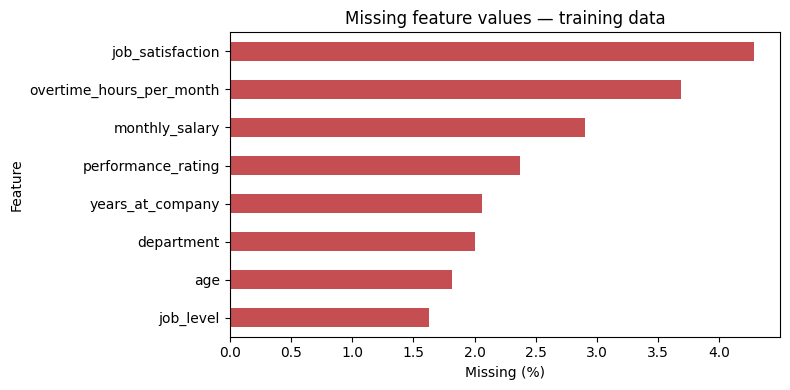

In [39]:
display(train.head())

summary = pd.DataFrame({
    "type": train.dtypes.astype(str),
    "missing": train.isna().sum(),
    "missing (%)": train.isna().mean() * 100,
    "unique_values": train.nunique(),
})

display(summary.round(2))

print("Repeated full source rows:", df.duplicated().sum())
print("Repeated predictor patterns in train:", train[FEATURES].duplicated().sum())
print("Missing or repeated employee IDs were checked before splitting.")

missing_share = train[FEATURES].isna().mean().mul(100).sort_values()

ax = missing_share.plot.barh(figsize=(8, 4), color="#C44E52")
ax.set(title="Missing feature values — training data", xlabel="Missing (%)", ylabel="Feature")
plt.tight_layout()
plt.show()


### Check ranges and category codes
Flags help identify possible data errors. They do not prove an error without a documented scale. Review flagged rows rather than silently deleting unusual employees.


**Code cell 6 — Check ranges and categories**

Summarizes numeric values and flags values outside the exercise checks. It also displays the frequency of each category, including missing values.

**Output:** Numeric statistics, flagged counts, and category tables. A flag needs investigation rather than automatic deletion.


In [40]:
display(train[NUMERIC + ["performance_rating"]].describe().round(2))

checks = {
    "age <= 0": (train["age"] <= 0).sum(),
    "years_at_company < 0": (train["years_at_company"] < 0).sum(),
    "monthly_salary <= 0": (train["monthly_salary"] <= 0).sum(),
    "overtime_hours_per_month < 0": (train["overtime_hours_per_month"] < 0).sum(),
    "job_satisfaction outside observed scale 1–100": (
        train["job_satisfaction"].notna() & ~train["job_satisfaction"].between(1, 100)
    ).sum(),
    "performance_rating outside codes 1–5": (
        train["performance_rating"].notna() & ~train["performance_rating"].isin([1, 2, 3, 4, 5])
    ).sum(),
}

display(pd.Series(checks, name="flagged_rows").to_frame())

for column in CATEGORICAL:
    print(f"\n{column}")
    display(train[column].value_counts(dropna=False).rename("rows").to_frame())


,age,years_at_company,monthly_salary,overtime_hours_per_month,job_satisfaction,performance_rating
count,3142.00,3134.00,3107.00,3082.00,3063.00,3124.00
mean,34.73,2.86,6404.55,6.77,59.99,2.97
std,8.22,2.54,3076.94,5.59,15.98,0.64
min,21.00,0.05,2350.00,0.00,1.00,1.00
25%,29.00,1.03,4200.00,3.00,49.00,3.00
50%,35.00,2.09,5500.00,5.00,60.00,3.00
75%,40.00,3.73,7700.00,9.00,70.00,3.00
max,62.00,22.00,24450.00,35.00,100.00,5.00


,flagged_rows
age <= 0,0
years_at_company < 0,0
monthly_salary <= 0,0
overtime_hours_per_month < 0,0
job_satisfaction outside observed scale 1–100,0
performance_rating outside codes 1–5,0



department


,rows
department,
Operations,515
Fulfillment,487
Customer Service,458
Retail Store,369
Sales,353
Marketing,246
Technology,219
Finance,185
Supply Chain,176



job_level


,rows
job_level,
Entry,1199
Mid,1115
Senior,606
Manager,228
NaN,52



performance_rating


,rows
performance_rating,
3.0,1899
2.0,646
4.0,557
NaN,76
5.0,12
1.0,10


### Check class balance
An always-stay classifier may look accurate when churn is rare. This is why we also measure precision, recall, F1 and average precision.


**Code cell 7 — Measure class imbalance**

Counts stay and churn labels, calculates their percentages, and shows how accurate an always-majority predictor would look.

**Output:** A balance table and bar chart. Use this to understand why accuracy alone can be misleading.


,rows,share (%)
churn,,
0,2808,87.75
1,392,12.25


Majority-only training accuracy: 87.75%


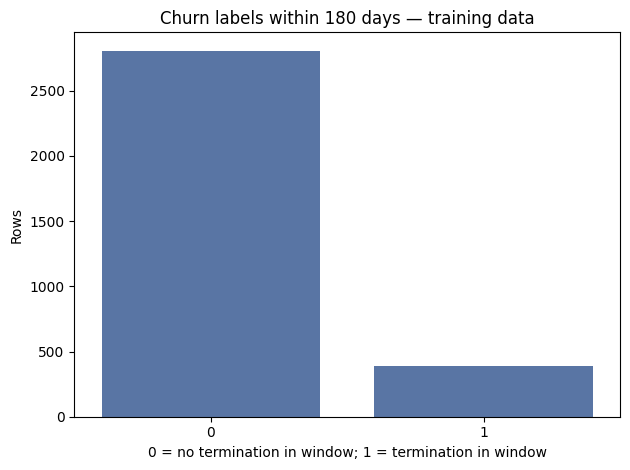

In [41]:
target_summary = train[TARGET].value_counts().reindex([0, 1], fill_value=0).to_frame("rows")
target_summary["share (%)"] = target_summary["rows"] / len(train) * 100

display(target_summary.round(2))
print(f"Majority-only training accuracy: {target_summary['share (%)'].max():.2f}%")

ax = sns.countplot(data=train, x=TARGET, order=[0, 1], color="#4C72B0")
ax.set(title=f"Churn labels within {HORIZON_DAYS} days — training data", xlabel="0 = no termination in window; 1 = termination in window", ylabel="Rows")
plt.tight_layout()
plt.show()


### Read numeric distributions
Histograms show where values are common and whether long tails exist. We do not remove a high salary just because it is unusual.


**Code cell 8 — Plot numeric distributions**

Assigns readable unit labels and draws one histogram per numeric feature. The unused sixth plot is hidden.

**Output:** Histograms of age, tenure, salary, overtime, and satisfaction. Look for common ranges and long tails.


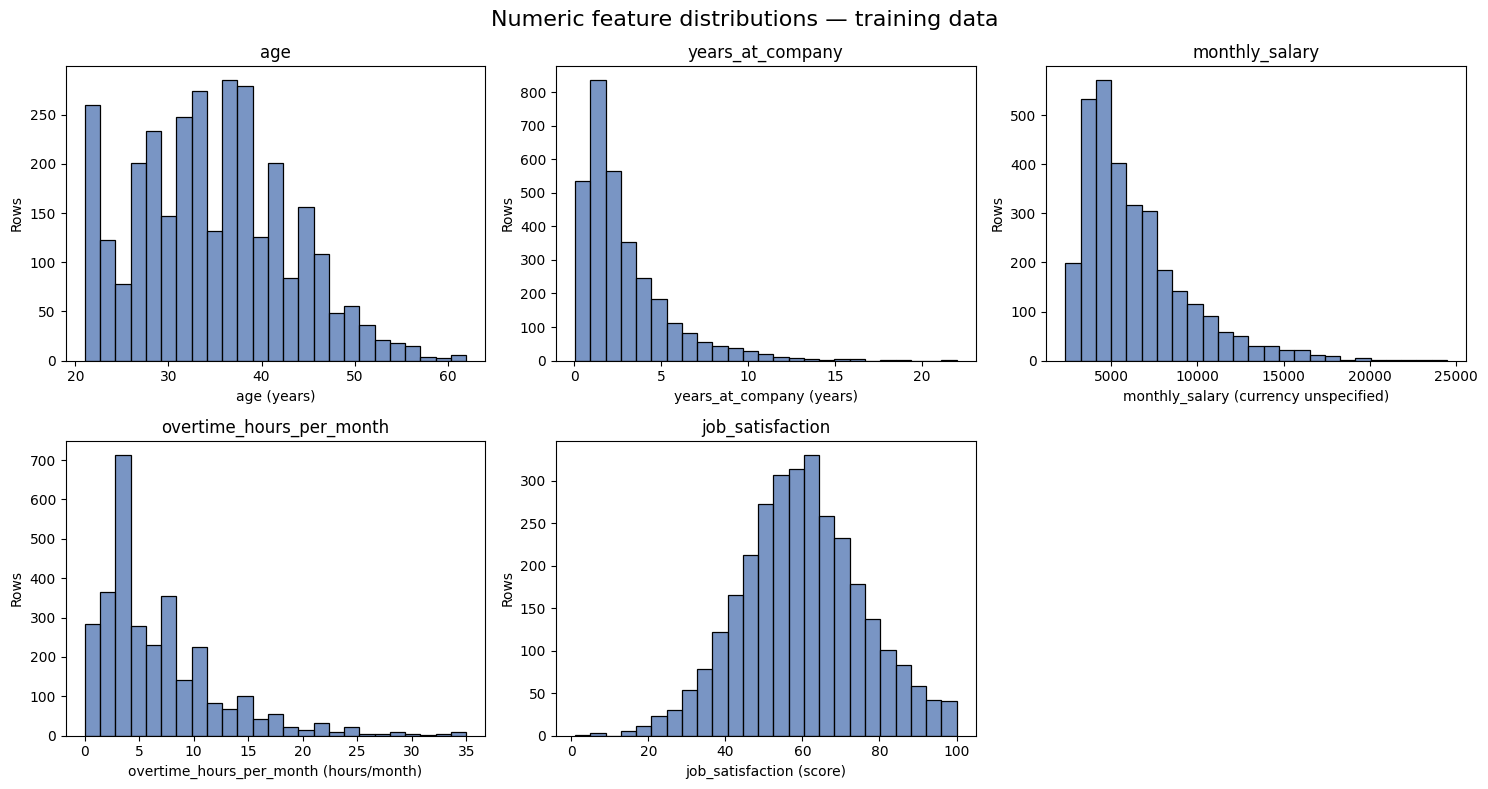

In [42]:
units = {"age": "years", "years_at_company": "years", "monthly_salary": "currency unspecified",
         "overtime_hours_per_month": "hours/month", "job_satisfaction": "score"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column in zip(axes.flat, NUMERIC):
    sns.histplot(data=train, x=column, bins=25, color="#4C72B0", ax=ax)
    ax.set(title=column, xlabel=f"{column} ({units[column]})", ylabel="Rows")

axes.flat[-1].set_visible(False)
fig.suptitle("Numeric feature distributions — training data", fontsize=16)
plt.tight_layout()
plt.show()


### Read category counts
Small groups provide less evidence. Missing categories are shown explicitly.


**Code cell 9 — Plot category frequencies**

Creates a plotting copy, labels missing categories, defines display order, and counts department, job level, and rating categories.

**Output:** Three category count charts. This changes plotting labels only; it does not modify model inputs.


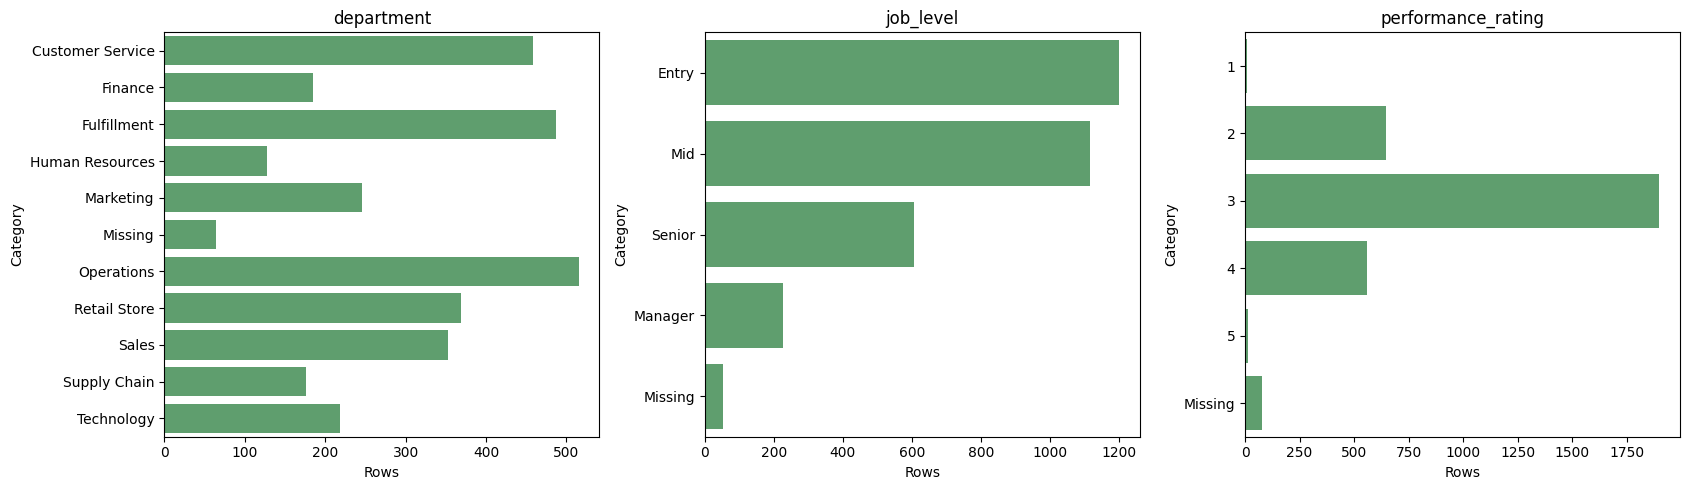

In [43]:
plot_data = train.copy()

for column in ["department", "job_level"]:
    plot_data[column] = plot_data[column].fillna("Missing")

plot_data["performance_rating"] = plot_data["performance_rating"].apply(
    lambda value: "Missing" if pd.isna(value) else str(int(value))
)

orders = {
    "department": sorted(plot_data["department"].unique()),
    "job_level": [level for level in ["Entry", "Mid", "Senior", "Manager", "Missing"] if level in plot_data["job_level"].values],
    "performance_rating": [level for level in ["1", "2", "3", "4", "5", "Missing"] if level in plot_data["performance_rating"].values],
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, column in zip(axes, CATEGORICAL):
    sns.countplot(data=plot_data, y=column, order=orders[column], color="#55A868", ax=ax)
    ax.set(title=column, xlabel="Rows", ylabel="Category")

plt.tight_layout()
plt.show()


### Compare distributions by churn
Separating the classes can suggest useful features. A difference is an association, not proof that the feature causes churn.


**Code cell 10 — Compare numeric features between classes**

Draws separate histograms for stay and churn employees. Density normalization makes the distributions comparable even when class sizes differ.

**Output:** Overlaid distributions. Differences suggest associations but do not prove causes of churn.


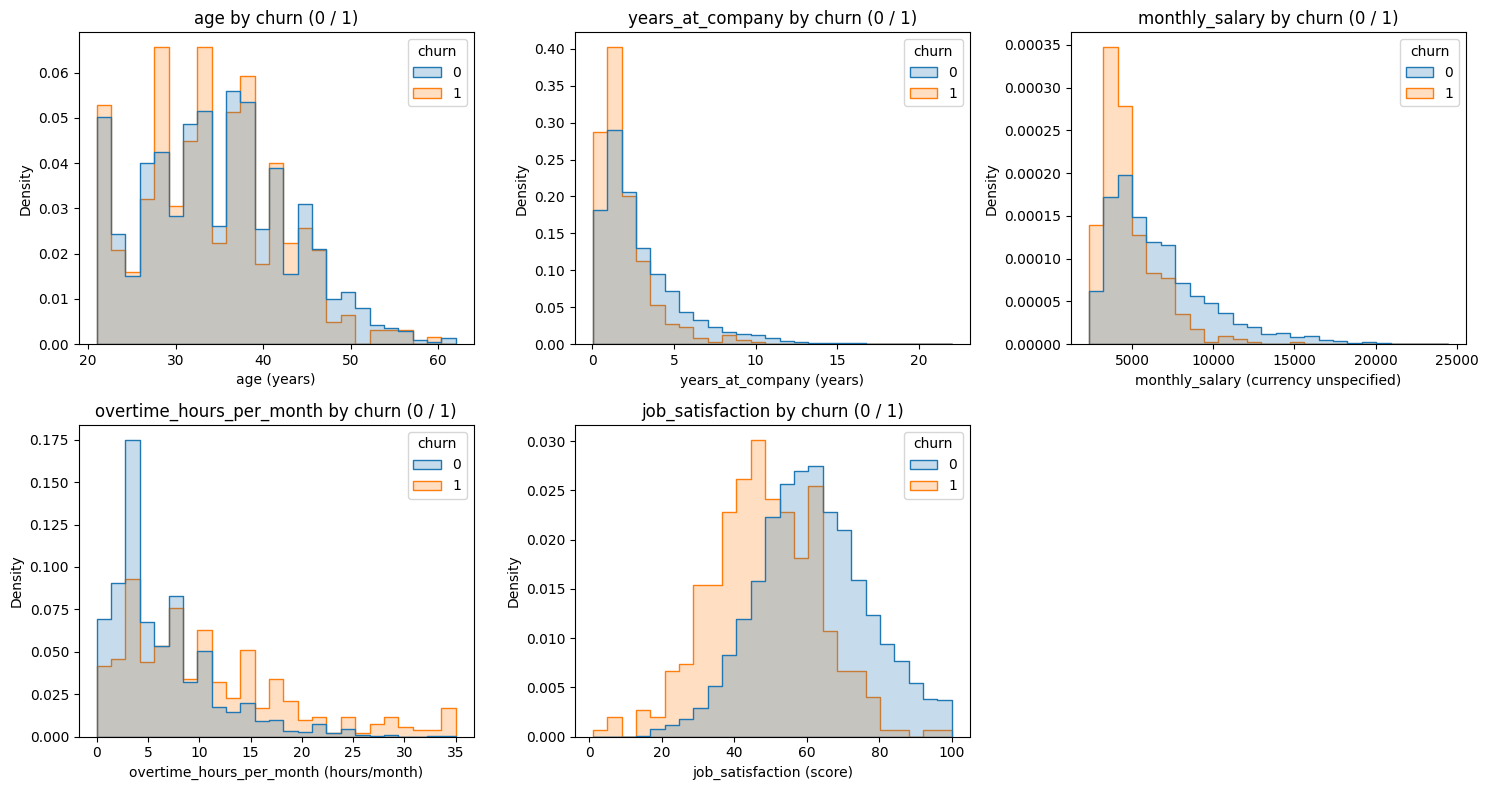

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column in zip(axes.flat, NUMERIC):
    sns.histplot(data=train, x=column, hue=TARGET, bins=25,
                 stat="density", common_norm=False, element="step", ax=ax)
    ax.set(title=f"{column} by churn (0 / 1)", xlabel=f"{column} ({units[column]})")

axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()


### Compare category churn rates
Read the row counts beside the rates. A high rate in a tiny category may be unstable.


**Code cell 11 — Compare category churn rates**

Groups training employees by category, calculates row counts and churn percentages, and plots each category rate.

**Output:** Tables and horizontal bar charts. Read the row counts before trusting a high rate in a small group.



department


,rows,churn_rate
department,,
Customer Service,458,14.41
Finance,185,8.11
Fulfillment,487,18.89
Human Resources,128,9.38
Marketing,246,4.47
Missing,64,17.19
Operations,515,10.49
Retail Store,369,15.18
Sales,353,10.20



job_level


,rows,churn_rate
job_level,,
Entry,1199,20.35
Mid,1115,10.04
Senior,606,4.62
Manager,228,1.75
Missing,52,7.69



performance_rating


,rows,churn_rate
performance_rating,,
1,10,50.00
2,646,19.97
3,1899,12.11
4,557,2.87
5,12,0.00
Missing,76,15.79


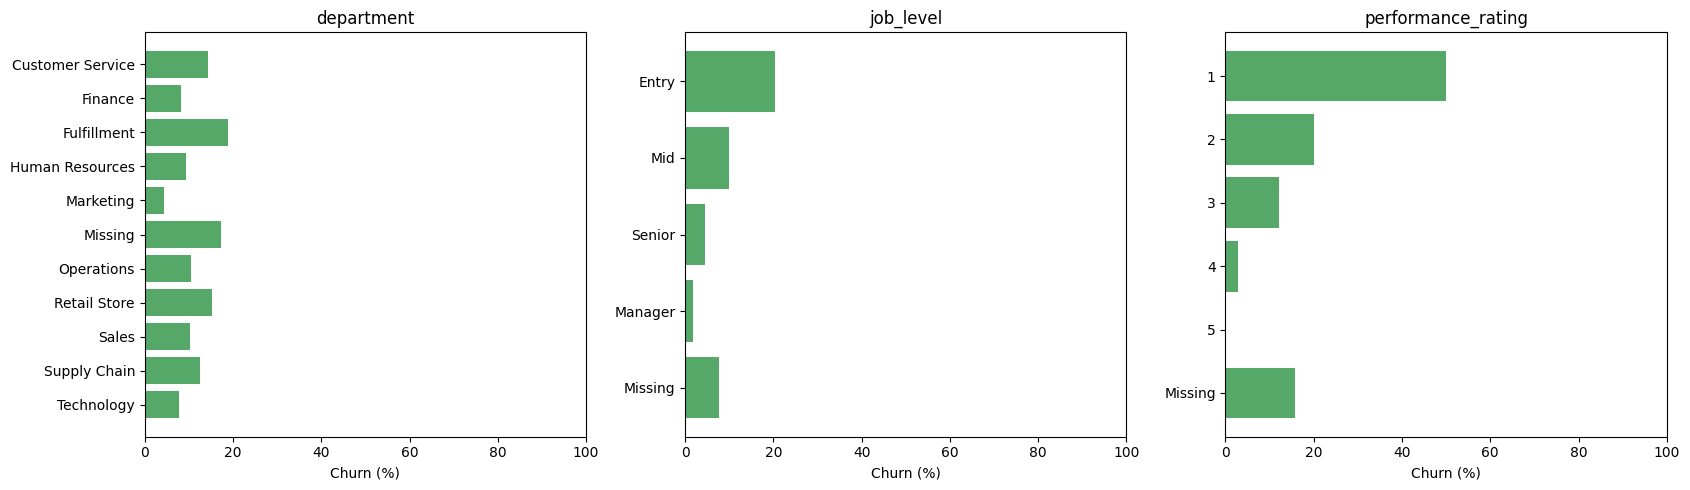

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, column in zip(axes, CATEGORICAL):
    group_summary = plot_data.groupby(column)[TARGET].agg(rows="size", churn_rate="mean").reindex(orders[column])
    group_summary["churn_rate"] *= 100

    print(f"\n{column}")
    display(group_summary.round(2))

    ax.barh(group_summary.index, group_summary["churn_rate"], color="#55A868")
    ax.invert_yaxis()
    ax.set(title=column, xlabel="Churn (%)", xlim=(0, 100))

plt.tight_layout()
plt.show()


### Compare satisfaction and overtime bands
These bands make the chart easier to read. Models still use the original numeric values; chart bands do not replace inputs.


**Code cell 12 — Compare satisfaction and overtime bands**

Places values into readable bands for charts, calculates each band’s churn share, and plots the results.

**Output:** Band summary tables and rate charts. The models still receive the original numeric features.


,rows,churn_rate
satisfaction_band,,
1–25,48,43.75
26–50,794,24.18
51–75,1719,8.84
76–100,502,2.39
Missing,137,10.95


,rows,churn_rate
overtime_band,,
0 hours,34,8.82
>0–5,1607,7.16
>5–10,849,12.25
>10–20,489,23.31
>20,103,38.83
Missing,118,13.56


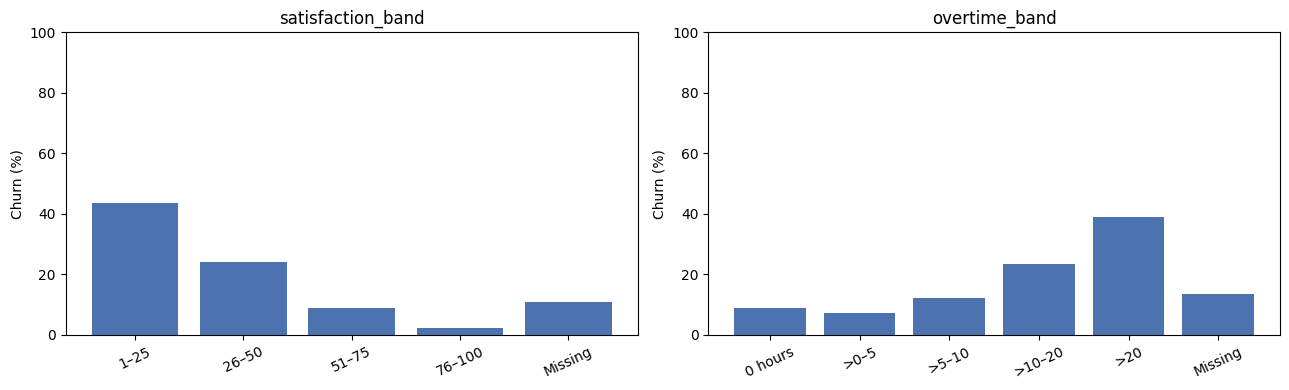

In [46]:
band_data = train.copy()

band_data["satisfaction_band"] = pd.cut(
    train["job_satisfaction"], bins=[0, 25, 50, 75, 100],
    labels=["1–25", "26–50", "51–75", "76–100"], include_lowest=True
).astype(object).fillna("Missing")

band_data["overtime_band"] = pd.cut(
    train["overtime_hours_per_month"], bins=[-np.inf, 0, 5, 10, 20, np.inf],
    labels=["0 hours", ">0–5", ">5–10", ">10–20", ">20"]
).astype(object).fillna("Missing")

band_orders = {"satisfaction_band": ["1–25", "26–50", "51–75", "76–100", "Missing"],
               "overtime_band": ["0 hours", ">0–5", ">5–10", ">10–20", ">20", "Missing"]}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, column in zip(axes, band_orders):
    group_summary = band_data.groupby(column)[TARGET].agg(rows="size", churn_rate="mean").reindex(band_orders[column])
    group_summary["churn_rate"] *= 100

    display(group_summary.round(2))

    ax.bar(group_summary.index, group_summary["churn_rate"], color="#4C72B0")
    ax.set(title=column, ylabel="Churn (%)", ylim=(0, 100))
    ax.tick_params(axis="x", labelrotation=25)

plt.tight_layout()
plt.show()


### Inspect correlations
Spearman correlation compares ranks and can show monotonic relationships. It does not capture every interaction. Numeric rating codes are used only for this descriptive chart; the models one-hot encode them.


**Code cell 13 — Calculate rank correlations**

Computes Spearman correlations for numeric features, rating codes, and churn, then displays a heatmap.

**Output:** A matrix with values from −1 to 1. It summarizes rank associations, not every possible interaction.


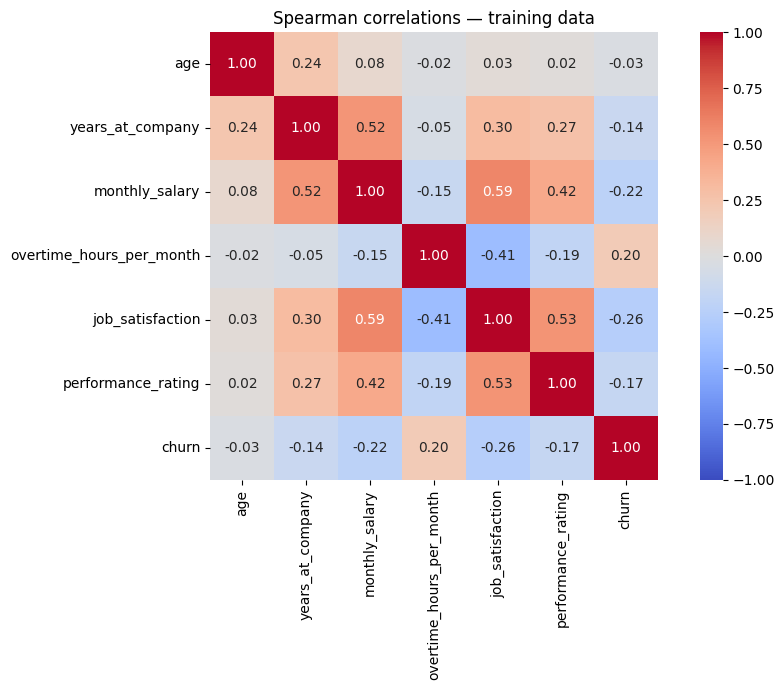

In [47]:
correlation_columns = NUMERIC + ["performance_rating", TARGET]

plt.figure(figsize=(10, 7))

correlation = train[correlation_columns].corr(method="spearman")

sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True)
plt.title("Spearman correlations — training data")
plt.tight_layout()
plt.show()


### Compare average values
This cell now follows the split, so `train` exists. Group means are descriptive; distributions and sample counts still matter.


**Code cell 14 — Compare class averages**

Groups the training data by churn and computes mean values for selected columns.

**Output:** One row per class with average feature values. Use this together with the distribution charts.


In [48]:
columns = [
    "age",
    "years_at_company",
    "monthly_salary",
    "overtime_hours_per_month",
    "job_satisfaction",
    "performance_rating",
]

display(train.groupby("churn")[columns].mean().round(2))


,age,years_at_company,monthly_salary,overtime_hours_per_month,job_satisfaction,performance_rating
churn,,,,,,
0,34.82,2.99,6628.98,6.24,61.63,3.01
1,34.07,1.95,4798.82,10.61,48.25,2.68


## 4. Prepare the inputs with pandas
We replace the longer preprocessing pipeline with direct pandas steps.

1. Select the eight features. Leave out IDs and termination dates.
2. Fill numeric gaps using **training medians**. A median is less affected by very large values than a mean.
3. Fill category gaps with `Missing`, then use `get_dummies()` to create one column per category. We do not treat category codes as measured distances.
4. Give validation exactly the training columns. A new category becomes zeros in the known columns.
5. Standardize numeric columns for neural networks using training means and standard deviations.

The small `encode_features()` function repeats steps 1–4. Its first argument is always the data allowed to teach the cleaning steps. Its second argument is transformed using those steps. The same rule applies inside MTKD folds.


**Code cell 15 — Fill missing values and encode categories**

Defines `encode_features()`. It learns numeric medians and category columns from its first dataset and applies them to the second dataset. It then prepares training, validation, and test features without IDs or outcome dates.

**Output:** Encoded feature tables for the teachers and student. Unknown categories cannot add new predictor columns.


In [49]:
def encode_features(training_data, new_data):
    training_features = training_data[FEATURES].copy()
    new_features = new_data[FEATURES].copy()

    for column in NUMERIC:
        training_features[column] = pd.to_numeric(training_features[column], errors='raise')
        new_features[column] = pd.to_numeric(new_features[column], errors='raise')

        if np.isinf(training_features[column].dropna()).any() or np.isinf(new_features[column].dropna()).any():
            raise ValueError(f'Infinite values in {column}')

        median = training_features[column].median()
        if pd.isna(median):
            median = 0  # Keeps a completely missing numeric column usable.

        training_features[column] = training_features[column].fillna(median)
        new_features[column] = new_features[column].fillna(median)

    for column in CATEGORICAL:

        training_features[column] = training_features[column].fillna('Missing').astype(str)
        new_features[column] = new_features[column].fillna('Missing').astype(str)

    training_features = pd.get_dummies(training_features, columns=CATEGORICAL, dtype=float)
    new_features = pd.get_dummies(new_features, columns=CATEGORICAL, dtype=float)

    new_features = new_features.reindex(columns=training_features.columns, fill_value=0)

    return training_features, new_features

train_features, val_features = encode_features(train, val)


### Scale numeric columns
`fit_transform` learns the training statistics. `transform` reuses them for other data. One-hot category columns stay as zeros and ones.


**Code cell 16 — Scale neural inputs and prepare labels**

Fits a scaler on training numeric columns, reuses it on validation columns, and converts the tables and labels to NumPy arrays. One-hot columns are not scaled.

**Output:** `X_train`, `X_val`, `X_test`, the three label arrays, and the encoded feature count.


In [50]:
scaler = StandardScaler()

train_scaled = train_features.copy()
val_scaled = val_features.copy()

train_scaled[NUMERIC] = scaler.fit_transform(train_features[NUMERIC])
val_scaled[NUMERIC] = scaler.transform(val_features[NUMERIC])

X_train = train_scaled.to_numpy(dtype=np.float32)
X_val = val_scaled.to_numpy(dtype=np.float32)

y_train = train['churn'].to_numpy(dtype=np.int64)
y_val = val['churn'].to_numpy(dtype=np.int64)

input_size = X_train.shape[1]
print('Input features after encoding:', input_size)


Input features after encoding: 27


## 5. Training settings and validation-based checkpoint selection

**Code cell 17 — Set the experiment choices and network**

Teachers train for at most 100 epochs; the student for at most 150. Validation AP selects checkpoints. Stop after 15 consecutive epochs without an improvement greater than 0.0001, then restore the checkpoint with the highest AP observed. Small improvements update the best checkpoint but only a sufficiently large improvement resets patience.

Internal validation is 20% of each OOF training fold. `TARGET_RECALL = 0.80` is the example threshold objective; choose a suitable target before running. The fixed 0.5 threshold is retained only for monitoring and comparison. `FRESH_TEST_PATH = None` uses the previously viewed held-out split for diagnostics.


In [51]:
# Plain variables make the settings easy to find and understand.
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

BATCH_SIZE = 64
EPOCHS = 150
TEACHER_EPOCHS = 100

TEMPERATURE = 2.0
LABEL_WEIGHT = 0.5

THRESHOLD = 0.5
PATIENCE = 15
MIN_DELTA = 0.0001
INNER_VAL_SHARE = 0.20
TARGET_RECALL = 0.80
FRESH_TEST_PATH = None  # Optional genuinely new employee CSV; same schema
LOG_EVERY = 10

# Two hidden layers, followed by two class scores: Stay and Churn.
def make_network(number_of_inputs, first_size, second_size):
    return nn.Sequential(
        nn.Linear(number_of_inputs, first_size),
        nn.ReLU(),
        nn.Linear(first_size, second_size),
        nn.ReLU(),
        nn.Linear(second_size, 2)
    ).to(device)

# Convert model scores into class probabilities.
def predict(model, inputs):
    model.eval()

    inputs = torch.tensor(inputs, dtype=torch.float32, device=device)

    with torch.no_grad():
        scores = model(inputs)
        probabilities = torch.softmax(scores, dim=1)

    return probabilities.cpu().numpy()

# Use a common probability interface for PyTorch and scikit-learn teachers.
def teacher_predict(model, inputs):
    if isinstance(model, nn.Module):
        return predict(model, inputs)
    return model.predict_proba(inputs)

# Progress updates each epoch; score messages appear every LOG_EVERY epochs.
# Fold plots are optional: OOF has selection and refit runs.
SHOW_FOLD_PLOTS = False
training_runs = {}


### Train, monitor, stop, and restore

**Code cell 18 — Define teacher training helpers**

The optimizer sees only training batches. Validation AP selects the best weights and controls stopping; validation never supplies gradients. `tqdm` advances each epoch and prints validation metrics every 10 epochs and at stopping. No test data enters these helpers.

For an OOF refit, pass no validation data and train for the duration already selected by internal validation. Save learning histories and the selected epoch for diagnostic plots.


In [52]:
def performance_scores(labels, probabilities):
    predictions = (probabilities >= THRESHOLD).astype(int)

    return {
        'accuracy': accuracy_score(labels, predictions),
        'F1': f1_score(labels, predictions, zero_division=0),
        'AP': average_precision_score(labels, probabilities),
        'logloss': log_loss(labels, probabilities, labels=[0, 1])
    }


def monitor_epoch(model, run_name, epoch, training_loss, validation_data, total_epochs):
    row = {'epoch': epoch, 'training_loss': training_loss}

    if validation_data is not None:
        val_inputs, val_labels = validation_data
        scores = performance_scores(val_labels, predict(model, val_inputs)[:, 1])

        for metric, value in scores.items():
            row['val_' + metric] = value

    if epoch % LOG_EVERY == 0 or epoch == total_epochs:
        message = f'{run_name} | Epoch {epoch:03d} | Train loss {training_loss:.4f}'

        if validation_data is not None:
            message += (f" | Val AP {row['val_AP']:.4f}, "
                        f"F1 {row['val_F1']:.4f}, "
                        f"accuracy {row['val_accuracy']:.4f}, "
                        f"log loss {row['val_logloss']:.4f}")

        tqdm.write(message)

    return row


def train_network(model, inputs, labels, epochs, run_name, validation_data=None):
    dataset = TensorDataset(torch.tensor(inputs, dtype=torch.float32),
                            torch.tensor(labels, dtype=torch.long))
    batches = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE,
                                 weight_decay=WEIGHT_DECAY)
    history = []
    best_AP = -np.inf
    patience_AP = -np.inf
    best_weights = None
    best_epoch = epochs
    stale_epochs = 0

    for epoch in tqdm(range(1, epochs + 1), desc=run_name, unit='epoch'):
        model.train()
        total_loss = 0

        for batch_inputs, batch_labels in batches:
            batch_inputs = batch_inputs.to(device)
            batch_labels = batch_labels.to(device)
            loss = F.cross_entropy(model(batch_inputs), batch_labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(batch_labels)

        average_loss = total_loss / len(dataset)
        row = monitor_epoch(model, run_name, epoch, average_loss, validation_data, epochs)
        history.append(row)

        if validation_data is not None:
            current_AP = row['val_AP']

            if current_AP > best_AP:
                best_AP = current_AP
                best_epoch = epoch
                best_weights = copy.deepcopy(model.state_dict())

            if current_AP > patience_AP + MIN_DELTA:
                patience_AP = current_AP
                stale_epochs = 0
            else:
                stale_epochs += 1

            if stale_epochs >= PATIENCE:
                tqdm.write(f'{run_name}: early stop at {epoch}; best epoch {best_epoch}, AP {best_AP:.4f}')
                break

    if best_weights is not None:
        model.load_state_dict(best_weights)
        tqdm.write(f'{run_name}: restored epoch {best_epoch}, validation AP {best_AP:.4f}')

    training_runs[run_name] = {
        'history': pd.DataFrame(history), 'best_epoch': best_epoch
    }

    return best_epoch


## 6. Adapted multi-teacher knowledge distillation

The three teachers now use different learning methods: a 128 → 64 neural network, logistic regression, and histogram gradient boosting. The student remains 32 → 16. This tests whether different model types give more useful soft targets on tabular data; it does not guarantee better performance.

### Step 1: produce out-of-fold teacher predictions

**Code cell 19 — Fit three teachers without using the held-out fold**

For each outer fold, fit preprocessing only on the outer training rows. For the neural teacher, use a further internal validation split to select its training duration, then refit on the whole outer training fold. The logistic and boosting teachers have fixed settings and fit on the whole outer training fold. Each predicts only the held-out fold. Compare their out-of-fold AP and prediction correlations to see whether they provide different information.


In [53]:
mtkd_start = time.perf_counter()
teacher_names = ['Neural network', 'Logistic regression', 'Histogram boosting']
teacher_seeds = [SEED + 10, SEED + 20, SEED + 30]
oof_predictions = np.zeros((len(train), len(teacher_names)))
folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
oof_epoch_rows = []


def prepare_pair(learn_rows, other_rows):
    learn_features, other_features = encode_features(learn_rows, other_rows)
    local_scaler = StandardScaler()
    learn_features[NUMERIC] = local_scaler.fit_transform(learn_features[NUMERIC])
    other_features[NUMERIC] = local_scaler.transform(other_features[NUMERIC])

    return (learn_features.to_numpy(dtype=np.float32),
            other_features.to_numpy(dtype=np.float32))


def make_sklearn_teacher(name, seed):
    if name == 'Logistic regression':
        return LogisticRegression(C=1.0, max_iter=1000, random_state=seed)
    if name == 'Histogram boosting':
        return HistGradientBoostingClassifier(
            learning_rate=0.05, max_iter=100, max_leaf_nodes=15,
            min_samples_leaf=20, l2_regularization=1.0,
            early_stopping=False, random_state=seed
        )
    raise ValueError(f'Unknown scikit-learn teacher: {name}')


for fold_number, (learn_indices, hold_indices) in enumerate(folds.split(train, y_train), start=1):
    inner_learn, inner_val = train_test_split(
        learn_indices, test_size=INNER_VAL_SHARE,
        stratify=y_train[learn_indices], random_state=SEED + fold_number
    )

    assert set(inner_learn).isdisjoint(inner_val)
    assert set(inner_learn).isdisjoint(hold_indices)
    assert set(inner_val).isdisjoint(hold_indices)

    inner_inputs, inner_val_inputs = prepare_pair(
        train.iloc[inner_learn], train.iloc[inner_val]
    )
    outer_inputs, hold_inputs = prepare_pair(
        train.iloc[learn_indices], train.iloc[hold_indices]
    )

    seed = teacher_seeds[0] + fold_number
    set_seed(seed)
    neural_teacher = make_network(inner_inputs.shape[1], 128, 64)
    selected_epochs = train_network(
        neural_teacher, inner_inputs, y_train[inner_learn], TEACHER_EPOCHS,
        run_name=f'OOF fold {fold_number} neural selection',
        validation_data=(inner_val_inputs, y_train[inner_val])
    )

    set_seed(seed)
    neural_teacher = make_network(outer_inputs.shape[1], 128, 64)
    train_network(
        neural_teacher, outer_inputs, y_train[learn_indices], selected_epochs,
        run_name=f'OOF fold {fold_number} neural refit'
    )
    oof_predictions[hold_indices, 0] = teacher_predict(neural_teacher, hold_inputs)[:, 1]
    oof_epoch_rows.append({'Fold': fold_number, 'Neural teacher epochs': selected_epochs})

    for teacher_number, name in enumerate(teacher_names[1:], start=1):
        teacher = make_sklearn_teacher(name, teacher_seeds[teacher_number] + fold_number)
        teacher.fit(outer_inputs, y_train[learn_indices])
        oof_predictions[hold_indices, teacher_number] = teacher_predict(teacher, hold_inputs)[:, 1]

assert np.isfinite(oof_predictions).all()
display(pd.DataFrame(oof_epoch_rows))
display(pd.DataFrame({
    'Teacher': teacher_names,
    'OOF AP': [average_precision_score(y_train, oof_predictions[:, i])
               for i in range(len(teacher_names))]
}).round(4))
display(pd.DataFrame(oof_predictions, columns=teacher_names).corr().round(3))


OOF fold 1 neural selection:   0%|          | 0/100 [00:00<?, ?epoch/s]

OOF fold 1 neural selection | Epoch 010 | Train loss 0.3122 | Val AP 0.4184, F1 0.2540, accuracy 0.8899, log loss 0.3038
OOF fold 1 neural selection: early stop at 18; best epoch 3, AP 0.4454
OOF fold 1 neural selection: restored epoch 3, validation AP 0.4454


OOF fold 1 neural refit:   0%|          | 0/3 [00:00<?, ?epoch/s]

OOF fold 1 neural refit | Epoch 003 | Train loss 0.3229


OOF fold 2 neural selection:   0%|          | 0/100 [00:00<?, ?epoch/s]

...

OOF fold 3 neural refit:   0%|          | 0/6 [00:00<?, ?epoch/s]

OOF fold 3 neural refit | Epoch 006 | Train loss 0.3116


,Fold,Neural teacher epochs
0,1,3
1,2,14
2,3,6


,Teacher,OOF AP
0,Neural network,0.3357
1,Logistic regression,0.3520
2,Histogram boosting,0.3118


,Neural network,Logistic regression,Histogram boosting
Neural network,1.000,0.953,0.854
Logistic regression,0.953,1.000,0.864
Histogram boosting,0.854,0.864,1.000


### Step 2: learn aggregation and train full teachers

**Code cell 20 — Cross-fit the aggregator and fit full teachers**

The aggregator learns from the three out-of-fold probabilities. A second stratified cross-fit gives each training employee a soft target from an aggregator that did not fit that employee's label. An aggregator fitted on all training rows is used only for teacher-system diagnostics.

The full neural teacher restores its best validation-AP checkpoint. Logistic regression and boosting fit the complete training split with fixed settings. The student targets come from the out-of-fold teachers and cross-fitted aggregator, not these full teachers.

Temperature T = 2 softens the combined two-class probabilities. Frozen targets receive no gradients. This is not a fully nested estimate of the stacked system.


In [54]:
# Each training employee gets a meta-model prediction from a fit excluding that employee.
crossfit_probabilities = np.full((len(train), 2), np.nan)
meta_folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + 100)
for meta_train, meta_hold in meta_folds.split(oof_predictions, y_train):
    fold_aggregator = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000)
    fold_aggregator.fit(oof_predictions[meta_train], y_train[meta_train])
    crossfit_probabilities[meta_hold] = fold_aggregator.predict_proba(oof_predictions[meta_hold])

assert np.isfinite(crossfit_probabilities).all()

# Full fit is for evaluating the teacher system on separate cohorts only.
aggregator = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000)
aggregator.fit(oof_predictions, y_train)
print('Aggregation coefficients:', aggregator.coef_[0])
print('Aggregation intercept:', aggregator.intercept_[0])

teachers = []

set_seed(teacher_seeds[0])
neural_teacher = make_network(input_size, 128, 64)
train_network(neural_teacher, X_train, y_train, TEACHER_EPOCHS,
              run_name='Full neural teacher', validation_data=(X_val, y_val))
neural_teacher.eval()
for parameter in neural_teacher.parameters():
    parameter.requires_grad = False
teachers.append(neural_teacher)

for teacher_number, name in enumerate(teacher_names[1:], start=1):
    teacher = make_sklearn_teacher(name, teacher_seeds[teacher_number])
    teacher.fit(X_train, y_train)
    teachers.append(teacher)

# Convert OOF aggregation probabilities into softer two-class targets.
teacher_probabilities = crossfit_probabilities
teacher_probabilities = np.clip(teacher_probabilities, 1e-7, 1 - 1e-7)

teacher_probabilities = torch.tensor(teacher_probabilities, dtype=torch.float32)
soft_targets = torch.softmax(torch.log(teacher_probabilities) / TEMPERATURE, dim=1)


Aggregation coefficients: [2.45798448 2.84388029 0.97027786]
Aggregation intercept: -2.957553529567671


Full neural teacher:   0%|          | 0/100 [00:00<?, ?epoch/s]

Full neural teacher | Epoch 010 | Train loss 0.3075 | Val AP 0.2927, F1 0.0388, accuracy 0.8762, log loss 0.3443
Full neural teacher: early stop at 19; best epoch 4, AP 0.3008
Full neural teacher: restored epoch 4, validation AP 0.3008


### Step 3: train and select the small student

**Code cell 21 — Train with mixed loss and restore best validation AP**

`loss = 0.5 × label cross-entropy + 0.5 × T² × KL divergence`

Label loss compares predictions with real outcomes. KL divergence compares softened student probabilities with the fixed aggregated targets. T² compensates for the gradient-scale change caused by temperature.

The student uses validation AP for early stopping and checkpoint selection, just like the full teachers. Validation log loss is different from the mixed training objective. No test predictions are calculated here.


Adapted MTKD student:   0%|          | 0/150 [00:00<?, ?epoch/s]

Adapted MTKD student | Epoch 010 | Train loss 0.1620 | Val AP 0.3082, F1 0.1062, accuracy 0.8738, log loss 0.3323
Student: early stop at 18; best epoch 3, AP 0.3119
Student restored epoch: 3 | Validation AP: 0.3119


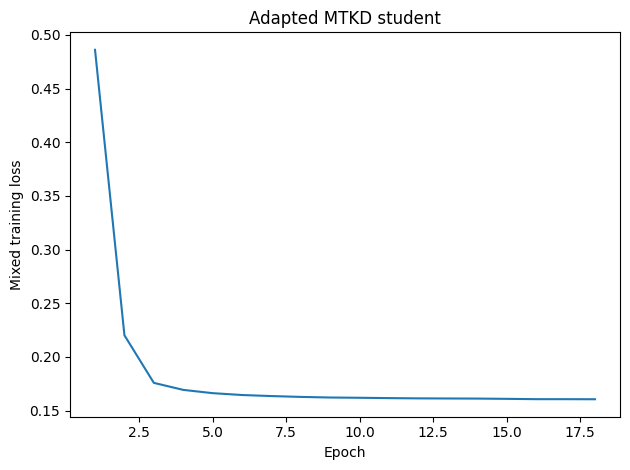

In [55]:
set_seed(SEED + 40)
student = make_network(input_size, 32, 16)

student_data = TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                             torch.tensor(y_train, dtype=torch.long),
                             soft_targets)

student_batches = DataLoader(student_data, batch_size=BATCH_SIZE, shuffle=True)

optimizer = torch.optim.Adam(student.parameters(), lr=LEARNING_RATE,
                             weight_decay=WEIGHT_DECAY)

student_losses = []
student_history = []
best_AP = -np.inf
patience_AP = -np.inf
best_epoch = 0
best_weights = None
stale_epochs = 0

# Fix the training seed for repeatable batch shuffling.
set_seed(SEED + 40)
student_progress = tqdm(range(EPOCHS), desc='Adapted MTKD student', unit='epoch')

for epoch in student_progress:
    student.train()
    total_loss = 0

    for batch_inputs, batch_labels, batch_targets in student_batches:
        batch_inputs = batch_inputs.to(device)
        batch_labels = batch_labels.to(device)
        batch_targets = batch_targets.to(device)

        scores = student(batch_inputs)
        label_loss = F.cross_entropy(scores, batch_labels)

        soft_loss = F.kl_div(F.log_softmax(scores / TEMPERATURE, dim=1),
                            batch_targets, reduction='batchmean')
        soft_loss = soft_loss * TEMPERATURE ** 2

        loss = LABEL_WEIGHT * label_loss + (1 - LABEL_WEIGHT) * soft_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(batch_labels)

    average_loss = total_loss / len(student_data)
    student_losses.append(average_loss)

    row = monitor_epoch(student, 'Adapted MTKD student', epoch + 1, average_loss,
                        (X_val, y_val), EPOCHS)
    student_history.append(row)

    if (epoch + 1) % LOG_EVERY == 0 or epoch + 1 == EPOCHS:
        student_progress.set_postfix(val_AP=f"{row['val_AP']:.3f}")

    current_AP = row['val_AP']

    if current_AP > best_AP:
        best_AP = current_AP
        best_epoch = epoch + 1
        best_weights = copy.deepcopy(student.state_dict())

    if current_AP > patience_AP + MIN_DELTA:
        patience_AP = current_AP
        stale_epochs = 0
    else:
        stale_epochs += 1

    if stale_epochs >= PATIENCE:
        tqdm.write(f'Student: early stop at {epoch + 1}; best epoch {best_epoch}, AP {best_AP:.4f}')
        break

student.load_state_dict(best_weights)
training_runs['Adapted MTKD student'] = {
    'history': pd.DataFrame(student_history), 'best_epoch': best_epoch
}
print('Student restored epoch:', best_epoch, '| Validation AP:', round(best_AP, 4))

mtkd_seconds = time.perf_counter() - mtkd_start

plt.plot(range(1, len(student_losses) + 1), student_losses)
plt.xlabel('Epoch')
plt.ylabel('Mixed training loss')
plt.title('Adapted MTKD student')
plt.tight_layout()
plt.show()


## 7. Training and validation curves

**Code cell 22 — Inspect overfitting and selected epochs**

Plots training loss plus validation log loss, AP, F1, and accuracy. A vertical line identifies the restored checkpoint; later points explain when stopping occurred. F1 and accuracy here still use 0.5. Fold plots are optional. There are no test curves.


Full neural teacher | selected epoch: 4


,epoch,training_loss,val_accuracy,val_F1,val_AP,val_logloss
3,4,0.3186,0.8762,0.0571,0.3008,0.3357


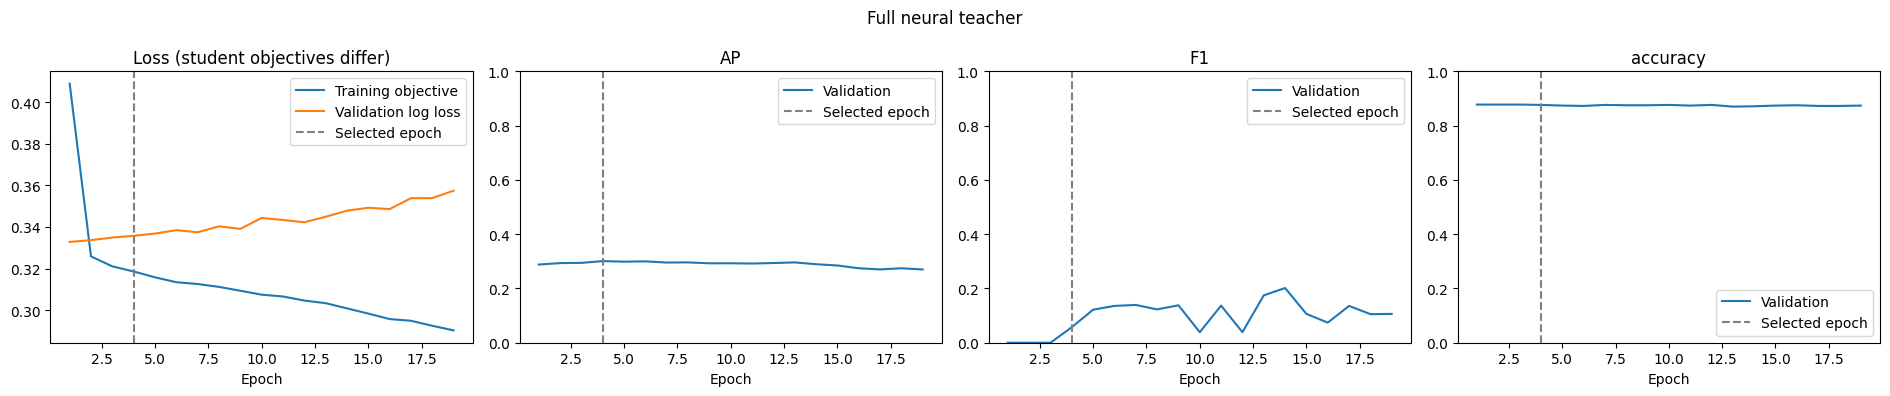

Adapted MTKD student | selected epoch: 3


,epoch,training_loss,val_accuracy,val_F1,val_AP,val_logloss
2,3,0.1759,0.8775,0.0,0.3119,0.331


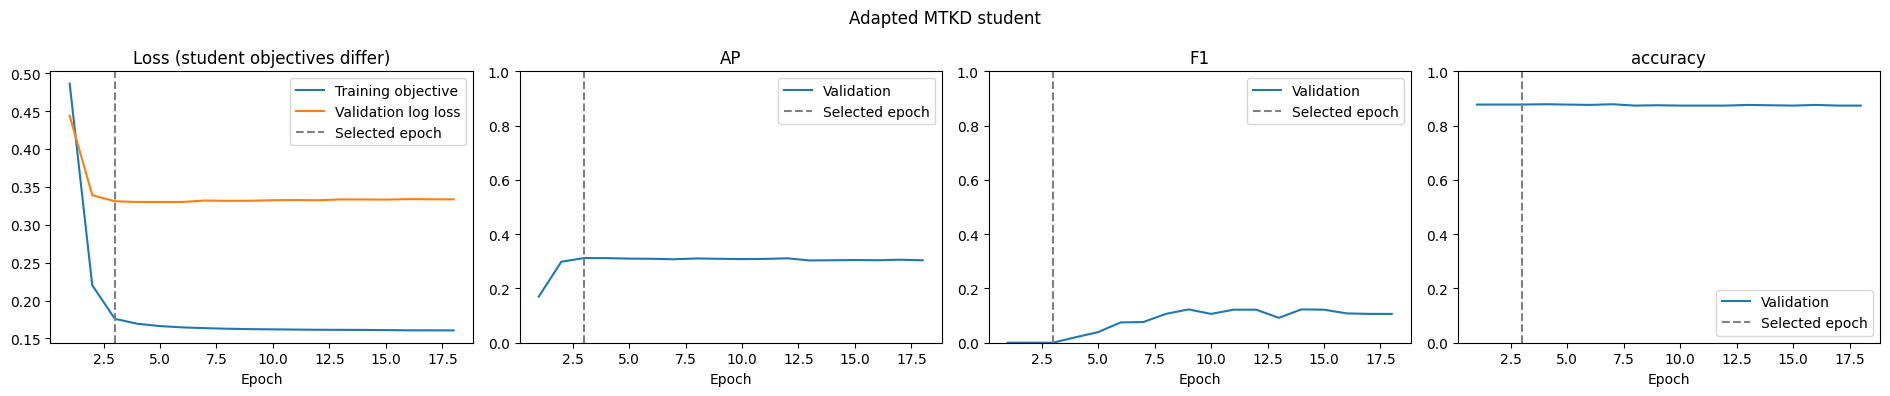

In [56]:
for run_name, run in training_runs.items():
    if run_name.startswith('OOF') and not SHOW_FOLD_PLOTS:
        continue

    history = run['history']
    print(run_name, '| selected epoch:', run['best_epoch'])
    display(history.loc[history['epoch'] == run['best_epoch']].round(4))
    fig, axes = plt.subplots(1, 4, figsize=(19, 4))
    axes[0].plot(history['epoch'], history['training_loss'], label='Training objective')

    if 'val_AP' in history:
        axes[0].plot(history['epoch'], history['val_logloss'], label='Validation log loss')

        for ax, metric in zip(axes[1:], ['AP', 'F1', 'accuracy']):
            ax.plot(history['epoch'], history['val_' + metric], label='Validation')
            ax.set_title(metric)
            ax.set_ylim(0, 1)

    axes[0].set_title('Loss (student objectives differ)')

    for ax in axes:
        ax.axvline(run['best_epoch'], linestyle='--', color='grey', label='Selected epoch')
        ax.set_xlabel('Epoch')
        ax.legend()

    fig.suptitle(run_name)
    plt.tight_layout()
    plt.show()
    plt.close(fig)


## 8. Choose the student threshold on validation only

**Code cell 23 — Fix the threshold before final evaluation**

Among all validation thresholds reaching `TARGET_RECALL`, choose the one with highest precision. Break precision ties by choosing the highest threshold. For example, target recall 80% asks to find at least 80% of actual churn cases on validation; it does not promise the same recall on future employees.

The table compares the chosen threshold with 0.5. AP, ROC-AUC, and log loss do not change when only the threshold changes. Recall can rise while precision and accuracy fall. This is a decision tradeoff, not proof of better probability estimates.


Validation recall target: 0.8
Selected threshold: 0.10220129042863846


,Accuracy,Precision,Recall,F1,ROC-AUC,AP,Log loss
Validation at 0.5,0.8775,0.0000,0.0000,0.0000,0.7436,0.3119,0.331
Validation at selected threshold,0.5650,0.1936,0.8061,0.3123,0.7436,0.3119,0.331


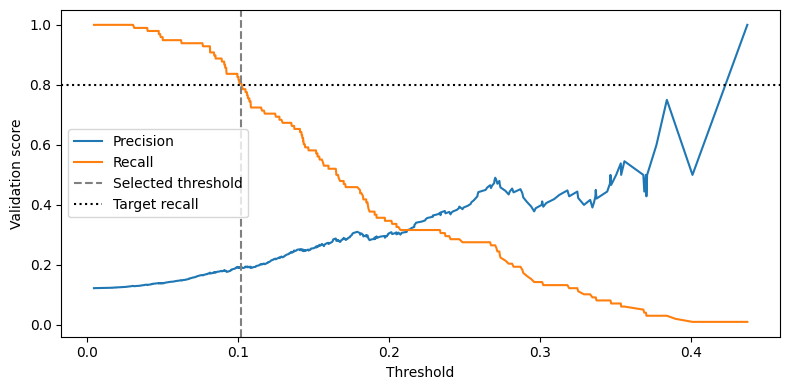

In [57]:
def evaluate(actual_labels, churn_probabilities, threshold=0.5):
    predicted_labels = (churn_probabilities >= threshold).astype(int)

    return {
        'Accuracy': accuracy_score(actual_labels, predicted_labels),
        'Precision': precision_score(actual_labels, predicted_labels, zero_division=0),
        'Recall': recall_score(actual_labels, predicted_labels, zero_division=0),
        'F1': f1_score(actual_labels, predicted_labels, zero_division=0),
        'ROC-AUC': roc_auc_score(actual_labels, churn_probabilities),
        'AP': average_precision_score(actual_labels, churn_probabilities),
        'Log loss': log_loss(actual_labels, churn_probabilities, labels=[0, 1])
    }

def choose_threshold(labels, probabilities, target_recall):
    if not 0 < target_recall <= 1:
        raise ValueError('TARGET_RECALL must be in (0, 1].')

    precision, recall, thresholds = precision_recall_curve(labels, probabilities)
    # The last precision/recall point has no corresponding threshold.
    candidates = pd.DataFrame({
        'Threshold': thresholds, 'Precision': precision[:-1], 'Recall': recall[:-1]
    })
    eligible = candidates.loc[candidates['Recall'] >= target_recall]

    if eligible.empty:
        raise ValueError('No threshold meets the target recall.')

    chosen = eligible.sort_values(
        ['Precision', 'Threshold'], ascending=[False, False]
    ).iloc[0]

    return float(chosen['Threshold']), candidates


val_mtkd = predict(student, X_val)[:, 1]
selected_threshold, threshold_candidates = choose_threshold(y_val, val_mtkd, TARGET_RECALL)
print('Validation recall target:', TARGET_RECALL)
print('Selected threshold:', selected_threshold)

display(pd.DataFrame({
    'Validation at 0.5': evaluate(y_val, val_mtkd, 0.5),
    'Validation at selected threshold': evaluate(y_val, val_mtkd, selected_threshold)
}).T.round(4))

plt.figure(figsize=(8, 4))
plt.plot(threshold_candidates['Threshold'], threshold_candidates['Precision'], label='Precision')
plt.plot(threshold_candidates['Threshold'], threshold_candidates['Recall'], label='Recall')
plt.axvline(selected_threshold, linestyle='--', color='grey', label='Selected threshold')
plt.axhline(TARGET_RECALL, linestyle=':', color='black', label='Target recall')
plt.xlabel('Threshold')
plt.ylabel('Validation score')
plt.legend()
plt.tight_layout()
plt.show()


### Labels-only baselines and validation decisions

**Code cell 24 — Compare distillation with simpler models**

Fit logistic regression and a student-sized network directly on labels. Both use the same training features. Select one threshold per model on validation, using the same 80% recall target. Validation scores guide model comparison; they are not independent performance estimates. Keep the final cohort untouched until the next section.


In [58]:
# Simple tabular baseline on exactly the same encoded training rows.
logistic_baseline = LogisticRegression(max_iter=1000, random_state=SEED)
logistic_baseline.fit(X_train, y_train)

# Architecture-matched control: same student size, labels only.
set_seed(SEED + 41)
labels_only = make_network(input_size, 32, 16)
train_network(labels_only, X_train, y_train, EPOCHS,
              run_name='Labels-only student', validation_data=(X_val, y_val))

validation_probabilities = {
    'MTKD student': val_mtkd,
    'Logistic regression': logistic_baseline.predict_proba(X_val)[:, 1],
    'Labels-only student': predict(labels_only, X_val)[:, 1],
}
model_thresholds = {'MTKD student': selected_threshold}
for name in ['Logistic regression', 'Labels-only student']:
    model_thresholds[name], _ = choose_threshold(
        y_val, validation_probabilities[name], TARGET_RECALL
    )

validation_rows = []
for name, probabilities in validation_probabilities.items():
    threshold = model_thresholds[name]
    validation_rows.append({
        'Model': name, 'Threshold': threshold,
        'Flagged': int((probabilities >= threshold).sum()),
        **evaluate(y_val, probabilities, threshold),
    })

print('Validation AP reference (churn share):', round(y_val.mean(), 4))
display(pd.DataFrame(validation_rows).set_index('Model').round(4))


Labels-only student:   0%|          | 0/150 [00:00<?, ?epoch/s]

Labels-only student | Epoch 010 | Train loss 0.3136 | Val AP 0.3093, F1 0.0762, accuracy 0.8788, log loss 0.3372
Labels-only student: early stop at 18; best epoch 3, AP 0.3291
Labels-only student: restored epoch 3, validation AP 0.3291
Validation AP reference (churn share): 0.1225


,Threshold,Flagged,Accuracy,Precision,Recall,F1,ROC-AUC,AP,Log loss
Model,,,,,,,,,
MTKD student,0.1022,408,0.5650,0.1936,0.8061,0.3123,0.7436,0.3119,0.3310
Logistic regression,0.0723,460,0.5100,0.1804,0.8469,0.2975,0.7247,0.3017,0.3377
Labels-only student,0.0878,439,0.5288,0.1822,0.8163,0.2980,0.7333,0.3291,0.3340


## 9. Final evaluation after all choices are fixed

**Code cell 25 — Load the final cohort and compare fixed decisions once**

With `FRESH_TEST_PATH = None`, use the original held-out employees and label results **reused-test diagnostics**. They were viewed earlier and cannot support a fresh unbiased performance claim.

With a new CSV, apply the same snapshot/window and follow-up assumption. Reject missing/repeated IDs, overlap with any original employee, invalid dates, or a single-class evaluation cohort. A new filename does not establish independence: independently verify the source, measurement timing, and complete outcome follow-up. A later prediction snapshot needs a separately specified time-based experiment.

Only now fit-free encoding and scaling are applied using training statistics. Generate probabilities for all three models and apply their validation-selected thresholds. Report flagged employees, true alerts, false alerts, and missed churn cases along with standard metrics. Do not tune choices after inspecting these results; that would require another untouched cohort.


In [59]:
if FRESH_TEST_PATH is None:
    evaluation_rows = test.copy()
    evaluation_status = 'REUSED-TEST DIAGNOSTICS (previously viewed split)'
else:
    fresh = pd.read_csv(FRESH_TEST_PATH)
    missing_columns = set(required) - set(fresh.columns)

    if missing_columns:
        raise ValueError(f'Missing fresh-test columns: {missing_columns}')

    if fresh['employee_id'].isna().any() or fresh['employee_id'].duplicated().any():
        raise ValueError('Fresh-test employee IDs must be present and unique.')

    if set(fresh['employee_id']) & set(df['employee_id']):
        raise ValueError('Fresh test must not contain any employee from the original CSV.')

    raw_dates = fresh['termination_date']
    fresh_dates = pd.to_datetime(raw_dates, errors='coerce')

    if (raw_dates.notna() & fresh_dates.isna()).any():
        raise ValueError('Invalid fresh-test termination dates.')

    if not ASSUME_COMPLETE_FOLLOWUP:
        raise ValueError('Verified complete follow-up is required.')

    fresh['termination_date'] = fresh_dates
    evaluation_rows = fresh.loc[~(fresh_dates.notna() & (fresh_dates <= SNAPSHOT_DATE))].copy()
    evaluation_rows[TARGET] = (
        evaluation_rows['termination_date'].gt(SNAPSHOT_DATE)
        & evaluation_rows['termination_date'].le(window_end)
    ).astype(int)
    evaluation_status = 'NEW-COHORT EVALUATION (independence/follow-up require source verification)'

if evaluation_rows[TARGET].nunique() != 2:
    raise ValueError('Final evaluation needs both stay and churn cases for these metrics.')

_, evaluation_features = encode_features(train, evaluation_rows)
evaluation_features[NUMERIC] = scaler.transform(evaluation_features[NUMERIC])
X_evaluation = evaluation_features.to_numpy(dtype=np.float32)
y_evaluation = evaluation_rows[TARGET].to_numpy(dtype=np.int64)
evaluation_probabilities = predict(student, X_evaluation)[:, 1]
final_probabilities = {
    'MTKD student': evaluation_probabilities,
    'Logistic regression': logistic_baseline.predict_proba(X_evaluation)[:, 1],
    'Labels-only student': predict(labels_only, X_evaluation)[:, 1],
}

print(evaluation_status)
print('Evaluation employees:', len(y_evaluation))
print('Actual churn:', int(y_evaluation.sum()))
print('AP reference (churn share):', round(y_evaluation.mean(), 4))

final_rows = []
for name, probabilities in final_probabilities.items():
    threshold = model_thresholds[name]
    flagged = probabilities >= threshold
    final_rows.append({
        'Model': name, 'Threshold': threshold,
        'Flagged': int(flagged.sum()),
        'True alerts': int((flagged & (y_evaluation == 1)).sum()),
        'False alerts': int((flagged & (y_evaluation == 0)).sum()),
        'Missed churn': int((~flagged & (y_evaluation == 1)).sum()),
        **evaluate(y_evaluation, probabilities, threshold),
    })

display(pd.DataFrame(final_rows).set_index('Model').round(4))


REUSED-TEST DIAGNOSTICS (previously viewed split)
Evaluation employees: 1000
Actual churn: 123
AP reference (churn share): 0.123


,Threshold,Flagged,True alerts,False alerts,Missed churn,Accuracy,Precision,Recall,F1,ROC-AUC,AP,Log loss
Model,,,,,,,,,,,,
MTKD student,0.1022,527,96,431,27,0.542,0.1822,0.7805,0.2954,0.7354,0.2850,0.335
Logistic regression,0.0723,585,106,479,17,0.504,0.1812,0.8618,0.2994,0.7282,0.2771,0.340
Labels-only student,0.0878,559,103,456,20,0.524,0.1843,0.8374,0.3021,0.7343,0.2896,0.336


### Confusion matrices and ranking curves

**Code cell 26 — Inspect final errors and ranking**

Compare the selected-threshold validation matrix with the final cohort matrix. False negatives are missed churn cases; false positives are employees incorrectly flagged. The final cohort recall can be below the validation recall target. ROC and precision–recall curves use the already generated probabilities.


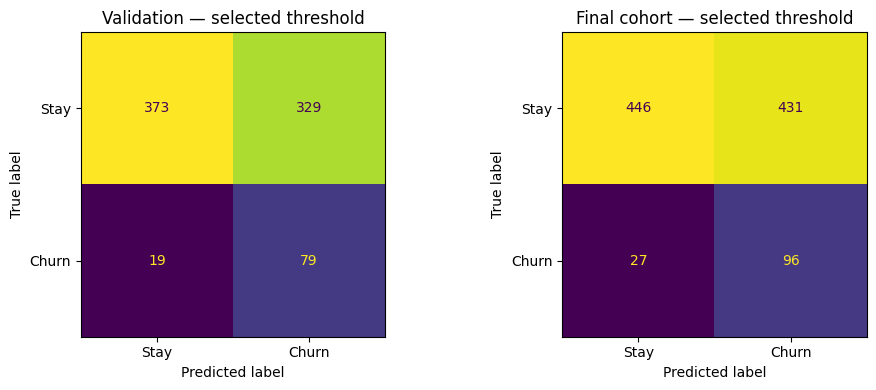

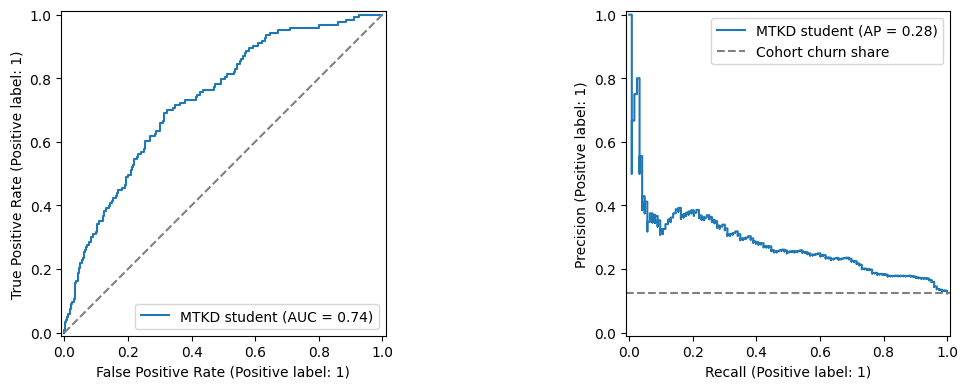

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, labels, probabilities, title in [
    (axes[0], y_val, val_mtkd, 'Validation'),
    (axes[1], y_evaluation, evaluation_probabilities, 'Final cohort')
]:
    ConfusionMatrixDisplay.from_predictions(
        labels, (probabilities >= selected_threshold).astype(int), labels=[0, 1],
        display_labels=['Stay', 'Churn'], colorbar=False, ax=ax
    )
    ax.set_title(title + ' — selected threshold')

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_evaluation, evaluation_probabilities, name='MTKD student', ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_evaluation, evaluation_probabilities, name='MTKD student', ax=axes[1])
axes[0].plot([0, 1], [0, 1], '--', color='grey')
axes[1].axhline(y_evaluation.mean(), linestyle='--', color='grey', label='Cohort churn share')
axes[1].legend()
plt.tight_layout()
plt.show()


### Diagnose the full teacher system after student choices are fixed

**Code cell 27 — Compare full teachers with their aggregation**

Report validation and final-cohort scores at 0.5 for teacher diagnostics. These scores must not be used to revise the completed experiment. Teacher-system inputs come from full teachers, whereas aggregation was learned from fold teachers; this distribution difference is a limitation.


In [61]:
val_teacher_predictions = np.column_stack([
    teacher_predict(teacher, X_val)[:, 1] for teacher in teachers
])
evaluation_teacher_predictions = np.column_stack([
    teacher_predict(teacher, X_evaluation)[:, 1] for teacher in teachers
])

val_aggregated = aggregator.predict_proba(val_teacher_predictions)[:, 1]
evaluation_aggregated = aggregator.predict_proba(evaluation_teacher_predictions)[:, 1]

for split_name, labels, probabilities, combined in [
    ('Validation', y_val, val_teacher_predictions, val_aggregated),
    ('Final cohort', y_evaluation, evaluation_teacher_predictions, evaluation_aggregated)
]:
    teacher_scores = {}

    for teacher_number in range(3):
        teacher_scores[teacher_names[teacher_number]] = evaluate(
            labels, probabilities[:, teacher_number]
        )

    teacher_scores['Aggregation system'] = evaluate(labels, combined)
    print(split_name, '— teacher system')
    display(pd.DataFrame(teacher_scores).T.round(4))


Validation — teacher system


,Accuracy,Precision,Recall,F1,ROC-AUC,AP,Log loss
Neural network,0.8762,0.4286,0.0306,0.0571,0.7301,0.3008,0.3357
Logistic regression,0.8762,0.4545,0.0510,0.0917,0.7247,0.3017,0.3377
Histogram boosting,0.8675,0.2778,0.0510,0.0862,0.7032,0.2702,0.3498
Aggregation system,0.8762,0.4706,0.0816,0.1391,0.7270,0.2974,0.3369


Final cohort — teacher system


,Accuracy,Precision,Recall,F1,ROC-AUC,AP,Log loss
Neural network,0.873,0.3750,0.0488,0.0863,0.7230,0.2741,0.3415
Logistic regression,0.875,0.4444,0.0650,0.1135,0.7282,0.2771,0.3400
Histogram boosting,0.876,0.4762,0.0813,0.1389,0.7057,0.2840,0.3474
Aggregation system,0.874,0.4400,0.0894,0.1486,0.7253,0.2818,0.3450


## 10. Model size, runtime, and limitations

**Code cell 28 — Report compression and training cost**

The student runs without teachers at prediction time. Runtime includes internal teacher selection, OOF refits, full teachers, aggregation, student training, and monitoring, but excludes final evaluation/reporting. Parameter counts are shown only for neural networks; tree and linear model parameters are not directly comparable. Fewer parameters do not by themselves prove lower prediction latency.


In [62]:
def parameter_count(model):
    return sum(parameter.numel() for parameter in model.parameters())

size_rows = [{'Model': 'MTKD student', 'Parameters': parameter_count(student)},
             {'Model': 'Labels-only student', 'Parameters': parameter_count(labels_only)}]

for name, teacher in zip(teacher_names, teachers):
    size_rows.append({
        'Model': name + ' teacher',
        'Parameters': parameter_count(teacher) if isinstance(teacher, nn.Module) else np.nan
    })

display(pd.DataFrame(size_rows))
print('MTKD full training and monitoring time:', round(mtkd_seconds, 2), 'seconds')


,Model,Parameters
0,MTKD student,1458.0
1,Labels-only student,1458.0
2,Neural network teacher,11970.0
3,Logistic regression teacher,NaN
4,Histogram boosting teacher,NaN


MTKD full training and monitoring time: 10.88 seconds


### How to report this experiment

Report selected teacher/student epochs, validation AP, the predeclared recall target, the selected threshold, and each model’s final-cohort precision/recall/F1/AP and alert counts. Identify whether the final cohort was new or the previously viewed split.

Early stopping limits unnecessary training; it does not guarantee improved AP. Lowering a threshold changes decisions, not ranking quality. A validation target does not guarantee future recall. One split and seed do not establish run-to-run stability. The original held-out data remain previously viewed, even though this version removes test monitoring. Use a genuinely new independently sourced cohort before claiming an independent final result.

Compare the MTKD student with both labels-only controls before claiming a benefit from distillation. Diverse teachers are a hypothesis to test, not an assurance of better AP. The cross-fitted aggregator targets remove direct in-sample fitting, but this is not a fully nested stacked-model evaluation. The Kaggle data and future outcomes are synthetic. Do not interpret this exercise as a validated real-world forecast.
